# ACT handover **v2** Monitor（三果依序 · trim12/15 乾淨100筆 · 照抄 basket ACT · 100k）

監控背景跑的 **v2 ACT** 訓練（`train_v2_all.sh`：apple → strawberry → banana 一條龍）。每次想看進度 → **Restart Kernel & Run All**。

## 這個 run 是什麼

**v2 handover ACT**：重收的乾淨資料（新 camera 拉近 + 三果 grasp/handover 修正 + 篩掉轉圈/甩飛/沒回home），三果各 **100 乾淨 ep**，轉檔時 **trim_motion lead12/trail15**（砍每筆頭 ~3s + 尾 ~11s 靜止）。ACT **無語言條件** → 每水果各訓一個。
- **預設看 apple_v2**（一條龍第一個，正在跑）。換 strawberry/banana 見下一個 cell 的註解三行。
- Dataset（trim 後）：**apple_v2 655/ep**、**strawberry_v2 657/ep**、**banana_v2 630/ep**（各 100 ep，比 v1 未trim 的 954/ep 乾淨很多）。
- **對照組 = v1**（未 trim、舊 camera/grasp）：40k 入籃 apple70/straw100/banana100；**入籃+回home apple50/straw90/banana10**（banana 回程差是 v2 主要要改善的）。

## 訓練配方（★照抄已跑通的 basket ACT = 單任務 90%；跟官方 ACT 文件對齊）

| | 說明 |
|---|---|
| Recipe | `--policy.type=act` + `chunk_size=60 / n_action_steps=1 / temporal_ensemble_coeff=0.01 / kl_weight=10`|
| Batch / lr | **8 / 1e-5**（官方文件建議 batch 8；lr 由 ACT preset 提供，**常數**無 schedule）· seed 42 |
| Steps / save | **100k / 10k（10 ckpt）** — 官方參考數字就是 100k；sweep 40/50/60k+ 挑甜蜜點（v1 都在 40k），**別預設 100k=最好** |
| 相機 / state | 3 相機（main + wrist_left + wrist_right）· 16D 從 dataset 自動推 |

**vs lerobot ACT 預設不同（故意的）**：預設 chunk=100、n_action_steps=100、temporal_ensemble_coeff=None（開環、關 temporal ensembling）→ 我們用論文原生的**閉環 temporal ensembling** 模式。

## 看數據時注意

- **unique_epochs ≈ 12**（100k×8 / ~65k frames）→ trim 後 frame 變少 + 100k 步 → 比 v1 的 5.9 高**約一倍**，**後段 ckpt 更容易 overfit**，務必 sweep 多個 ckpt 別只看 last。
- **Loss 尺度**：ACT = L1 重建 + KL（kl_weight=10），起手 ~7.x，收斂到 ~0.0x；別跟 SmolVLA flow-matching loss 直接比。
- **雙臂都動**：Action stats 左右臂 span 都 >0.5、0 個 zero-variance（handover 雙臂）。
- **temporal ensembling 開**（n_action_steps=1）→ 閉環才平滑；這是切 ACT 的核心理由，非「比較簡單」。
- basket：apple/strawberry → **紅籃**（成功終點 y≈-0.06）；banana → **黃籃**（y≈-0.18）。

In [1]:
from pathlib import Path
import re
import json
import matplotlib.pyplot as plt
import pandas as pd

# ── v2 handover ACT：三果依序 100k · trim12/15 乾淨100筆 · 照抄 basket ACT ──
# 預設看 apple_v2（一條龍第一個）。換其他果 → 改下面 LOG_PATH/OUTPUT_DIR 兩行即可。
LOG_PATH    = Path.home() / 'openarm_isaaclab/outputs/act_handover_apple_v2_train.log'
OUTPUT_DIR  = Path.home() / 'openarm_isaaclab/outputs/finetune_act_handover_apple_v2'
TOTAL_STEPS = 100000

# strawberry_v2:
# LOG_PATH   = Path.home() / 'openarm_isaaclab/outputs/act_handover_strawberry_v2_train.log'
# OUTPUT_DIR = Path.home() / 'openarm_isaaclab/outputs/finetune_act_handover_strawberry_v2'
# banana_v2:
# LOG_PATH   = Path.home() / 'openarm_isaaclab/outputs/act_handover_banana_v2_train.log'
# OUTPUT_DIR = Path.home() / 'openarm_isaaclab/outputs/finetune_act_handover_banana_v2'
#
# 範本 = basket ACT（單任務 basket 90%）:
# outputs/finetune_act_basket  (chunk_size=60, temporal_ensemble_coeff=0.01, kl_weight=10, batch 8, 100k)

print(f'Log: {LOG_PATH}  exists={LOG_PATH.exists()}  size={LOG_PATH.stat().st_size/1024:.1f} KB' if LOG_PATH.exists() else f'❌ Log NOT FOUND: {LOG_PATH}')
print(f'Output dir: {OUTPUT_DIR}  exists={OUTPUT_DIR.exists()}')
print(f'TOTAL_STEPS: {TOTAL_STEPS:,}')

Log: /home/teddyminelab/openarm_isaaclab/outputs/act_handover_apple_v2_train.log  exists=True  size=193.8 KB
Output dir: /home/teddyminelab/openarm_isaaclab/outputs/finetune_act_handover_apple_v2  exists=True
TOTAL_STEPS: 100,000


## 0. 訓練設定 + Dataset 資訊

從 train log 頂部 config dump + dataset `meta/info.json` 撈。靜態資訊，跑一次就夠。

In [2]:
import json
import glob
from pathlib import Path

# ── 1. 從 train log 頂部撈訓練 config ─────────────────────────────────────────
def extract_from_log(log_text: str, key: str) -> str | None:
    m = re.search(rf"'{re.escape(key)}'\s*:\s*([^,\n}}]+?)(?=,\n|\n[}}\s'])", log_text)
    return m.group(1).strip().strip("'") if m else None

KEYS_TRAIN  = ['batch_size', 'steps', 'save_freq', 'log_freq', 'num_workers', 'seed']
# ACT-specific policy keys（跟 SmolVLA 不同：無 VLM、有 temporal ensembling + CVAE）
KEYS_POLICY = ['chunk_size', 'n_action_steps', 'temporal_ensemble_coeff', 'kl_weight',
               'use_vae', 'latent_dim', 'dim_model', 'n_heads', 'dim_feedforward',
               'n_encoder_layers', 'n_decoder_layers', 'vision_backbone',
               'pretrained_backbone_weights', 'dropout']
KEYS_DATASET = ['repo_id', 'root']

print("=" * 65)
print("訓練設定（從 train.log 頂部 config dump 解析）")
print("=" * 65)

train_cfg_parsed = {}
if LOG_PATH.exists():
    head = '\n'.join(LOG_PATH.read_text(errors='ignore').splitlines()[:250])

    print("\n── Train pipeline ──")
    for k in KEYS_TRAIN:
        v = extract_from_log(head, k)
        if v:
            train_cfg_parsed[k] = v
            print(f"  {k:30s} = {v}")

    print("\n── ACT Policy ──")
    for k in KEYS_POLICY:
        v = extract_from_log(head, k)
        if v:
            train_cfg_parsed[k] = v
            print(f"  {k:30s} = {v}")

    # optimizer lr（ACT preset 提供，常數；'lr' 在 optimizer dict 內）
    v_lr = extract_from_log(head, 'lr')
    if v_lr:
        train_cfg_parsed['optimizer_lr'] = v_lr
        print(f"  {'optimizer_lr':30s} = {v_lr}")

    print("\n── Dataset ──")
    for k in KEYS_DATASET:
        v = extract_from_log(head, k)
        if v:
            train_cfg_parsed[k] = v
            print(f"  {k:30s} = {v}")
else:
    print(f"❌ Log not found: {LOG_PATH}")

# ── 2. Dataset 整體統計（從 meta/info.json 撈）─────────────────────────────
print("\n" + "=" * 65)
print("Dataset 整體統計")
print("=" * 65)

PROJECT_ROOT = Path.home() / 'openarm_isaaclab'
ds_root_str = train_cfg_parsed.get('root')
if ds_root_str:
    p = Path(ds_root_str)
    DS_ROOT = p if p.is_absolute() else (PROJECT_ROOT / p)
else:
    DS_ROOT = PROJECT_ROOT / 'datasets_lerobot/openarm/handover_apple'

print(f"  Dataset root: {DS_ROOT}  exists={DS_ROOT.exists()}")

info_path = DS_ROOT / 'meta' / 'info.json'
total_episodes = total_frames = fps = 0
action_dim = 16
if info_path.exists():
    info = json.loads(info_path.read_text())
    total_episodes = info.get('total_episodes', 0)
    total_frames = info.get('total_frames', 0)
    fps = info.get('fps', 30)
    action_dim = int(info.get('features', {}).get('action', {}).get('shape', [16])[0])

    duration_min = total_frames / fps / 60 if fps else 0
    avg_frames = total_frames / total_episodes if total_episodes else 0
    avg_sec = avg_frames / fps if fps else 0

    print(f"\n  Dataset version    : {info.get('codebase_version')}")
    print(f"  Total episodes     : {total_episodes:,} ep")
    print(f"  Total frames       : {total_frames:,}")
    dim_marker = '(16D bimanual) ⭐' if action_dim == 16 else ''
    print(f"  Action dim         : {action_dim} {dim_marker}")
    print(f"  FPS                : {fps}")
    print(f"  Total duration     : {duration_min:.1f} 分鐘 ({duration_min/60:.1f} 小時)")
    print(f"  Avg frames per ep  : {avg_frames:.0f} ({avg_sec:.1f} 秒/ep @ {fps} FPS)")
else:
    print(f"  ⚠️ info.json not found at {info_path}")

# ── 3. Episode length 分布 ────────────────────────────────────────────────
import pyarrow.parquet as pq
ep_files = sorted(glob.glob(str(DS_ROOT / 'meta' / 'episodes' / '**' / '*.parquet'), recursive=True))
if ep_files:
    import numpy as np
    ep_df = pq.read_table(ep_files[0], columns=['episode_index', 'length', 'tasks']).to_pandas()
    lengths = ep_df['length'].values
    print(f"\n  Episode length 分布（單位：frames）:")
    print(f"    min     = {lengths.min()}  ({lengths.min()/fps:.1f} 秒)")
    print(f"    p10     = {np.percentile(lengths, 10):.0f}")
    print(f"    median  = {np.median(lengths):.0f}  ({np.median(lengths)/fps:.1f} 秒)")
    print(f"    mean    = {lengths.mean():.0f}  ({lengths.mean()/fps:.1f} 秒)")
    print(f"    p90     = {np.percentile(lengths, 90):.0f}")
    print(f"    max     = {lengths.max()}  ({lengths.max()/fps:.1f} 秒)")

# ── 4. Features spec ─────────────────────────────────────────────────────
if info_path.exists():
    print(f"\n  Features ({len(info.get('features', {}))}):")
    for k, v in info.get('features', {}).items():
        shape = v.get('shape', '?')
        dtype = v.get('dtype', '?')
        marker = '🎥' if dtype == 'video' else ('📊' if isinstance(shape, list) and len(shape) == 1 else '  ')
        print(f"    {marker} {k:38s} {str(shape):20s} {dtype}")

# ── 5. 訓練資料覆蓋率 ─────────────────────────────────────────────────────
try:
    batch = int(train_cfg_parsed.get('batch_size', 0))
    steps = int(train_cfg_parsed.get('steps', 0))
    chunk = int(train_cfg_parsed.get('chunk_size', 60))
    if batch and steps and total_frames:
        frames_per_step = batch * chunk
        total_samples = steps * frames_per_step
        epochs_view = total_samples / total_frames
        unique_epochs = (steps * batch) / total_frames
        steps_per_epoch = total_frames / batch
        print(f"\n  訓練資料覆蓋率:")
        print(f"    每 step 採樣      : batch × chunk = {batch} × {chunk} = {frames_per_step} frame-views")
        print(f"    總 frame-views    : {steps:,} × {frames_per_step} = {total_samples:,}")
        print(f"    Frame-views/frame : {epochs_view:.1f}  (model 平均「touched」每個 frame {epochs_view:.1f} 次)")
        print(f"    Unique epochs    : {unique_epochs:.2f}  (= steps × batch / total_frames)")
        print(f"    Steps per epoch  : {steps_per_epoch:.0f}  (1 epoch ≈ 此 step 數)")
        if unique_epochs > 8:
            print(f"    ⚠️ unique_epochs={unique_epochs:.1f} 偏高 → 後段 ckpt 可能 overfit，sweep 多個 ckpt，別只看 last")
        elif unique_epochs > 4:
            print(f"    ℹ️ unique_epochs={unique_epochs:.1f} → 健康範圍；仍 sweep 20/30/40/50/60k 挑甜蜜點（押 30–50k）")
except (ValueError, TypeError):
    pass

# ── 6. 任務字串 ─────────────────────────────────────────────────────────────
tasks_path = DS_ROOT / 'meta' / 'tasks.parquet'
if tasks_path.exists():
    tasks_df = pd.read_parquet(tasks_path)
    print(f"\n  Task prompts ({len(tasks_df)}):  ※ ACT 不吃 language，這裡僅資訊")
    for task_str in tasks_df.index:
        print(f"    >>> {task_str!r}")

# ── 7. Action stats 健康檢查 ───────────────────────────────────────────────
stats_path = DS_ROOT / 'meta' / 'stats.json'
if stats_path.exists():
    stats = json.loads(stats_path.read_text())
    import numpy as np
    q01 = np.array(stats['action']['q01'])
    q99 = np.array(stats['action']['q99'])
    spans = q99 - q01
    print(f"\n  Action stats 健康檢查 ({action_dim}D, ACT = absolute joint):")
    if action_dim == 16:
        right_max = spans[:8].max()
        left_max  = spans[8:].max()
        print(f"    Right arm max span (idx 0-7) : {right_max:.4f}  {'(active ✓ 雙臂任務)' if right_max > 0.5 else '(frozen?! 預期右臂會動)'}")
        print(f"    Left arm  max span (idx 8-15): {left_max:.4f}  {'(active ✓)' if left_max > 0.5 else '(too narrow!)'}")
    print(f"    Narrow dims (span<0.01)    : {int((spans < 0.01).sum())} / {action_dim}  {'✓ no zero-variance' if (spans < 0.01).sum() == 0 else '⚠️ 有 zero-variance dim'}")

訓練設定（從 train.log 頂部 config dump 解析）

── Train pipeline ──
  batch_size                     = 8
  steps                          = 100000
  save_freq                      = 10000
  log_freq                       = 200
  num_workers                    = 4
  seed                           = 42

── ACT Policy ──
  chunk_size                     = 60
  n_action_steps                 = 1
  temporal_ensemble_coeff        = 0.01
  kl_weight                      = 10.0
  use_vae                        = True
  latent_dim                     = 32
  dim_model                      = 512
  n_heads                        = 8
  dim_feedforward                = 3200
  n_encoder_layers               = 4
  n_decoder_layers               = 1
  pretrained_backbone_weights    = ResNet18_Weights.IMAGENET1K_V1
  dropout                        = 0.1
  optimizer_lr                   = 1e-05

── Dataset ──
  repo_id                        = handover_apple_v2
  root                           = datasets_lerobot/o

## 1. Live progress + GPU VRAM

In [3]:
# ── Live progress + GPU VRAM ─────────────────────────────────────────────
# ACT (lerobot-train) tqdm 顯示 'step/s'（跟 SmolVLA 同）
# 範例： Training: 21%|██ | 12599/60000 [11:56<44:34, 17.72step/s]
import re
import subprocess
from datetime import timedelta

TQDM_RE = re.compile(
    r'(?P<step>\d+)/(?P<total>\d+)\s*\[(?P<elapsed>[\d:]+)<(?P<eta>[\d:]+|\?|\S+?),\s*(?P<rate>[\d.]+)(?P<unit>step/s|s/step)\]'
)

def _fmt_td(s):
    parts = s.split(':')
    if len(parts) == 2:
        parts = ['00'] + parts
    if len(parts) == 3:
        h, m, sec = parts
        return f"{int(h):2d}h {int(m):02d}m {int(sec):02d}s"
    return s

def _bar(pct: float, width: int = 40) -> str:
    filled = int(max(0, min(pct, 1.0)) * width)
    return '█' * filled + '░' * (width - filled)

# ── Block A: Training progress ────────────────────────────────────────────
print("─" * 70)
print(" TRAINING PROGRESS")
print("─" * 70)
if LOG_PATH.exists():
    raw = LOG_PATH.read_text(errors='ignore')
    matches = list(TQDM_RE.finditer(raw.replace('\r', '\n')))
    if matches:
        m = matches[-1]
        step  = int(m['step'])
        total = int(m['total'])
        pct   = step / total
        rate  = float(m['rate'])
        unit  = m['unit']
        if unit == 's/step':
            step_s = rate
            steps_per_s = 1.0 / rate if rate > 0 else 0
        else:
            steps_per_s = rate
            step_s = 1.0 / rate if rate > 0 else 0
        eta_sec = (total - step) * step_s

        print(f"  [{_bar(pct)}] {pct*100:5.1f}%")
        print(f"  Step    : {step:,} / {total:,}")
        print(f"  Speed   : {step_s:.3f}s/step  ({steps_per_s:.2f} step/s)")
        print(f"  Elapsed : {_fmt_td(m['elapsed'])}")
        print(f"  ETA     : {timedelta(seconds=int(eta_sec))}  (≈ {eta_sec/60:.1f}m, {eta_sec/3600:.1f}h)")
        import time as _t
        age = int(_t.time() - LOG_PATH.stat().st_mtime)
        freshness = "🟢 live" if age < 30 else ("🟡 stale" if age < 300 else "🔴 dead?")
        print(f"  Log age : {age}s ago  {freshness}")
    else:
        print("  ⏳ Training log exists but no tqdm progress yet (model loading).")
else:
    print(f"  ❌ Log not found: {LOG_PATH}")

# ── Block B: GPU VRAM ─────────────────────────────────────────────────────
print()
print("─" * 70)
print(" GPU VRAM")
print("─" * 70)
try:
    gpu_q = subprocess.check_output([
        'nvidia-smi',
        '--query-gpu=name,memory.used,memory.total,utilization.gpu,temperature.gpu,power.draw',
        '--format=csv,noheader,nounits',
    ]).decode().strip().split(', ')
    name, used_mb, total_mb, util, temp, power = gpu_q
    used_gb = float(used_mb) / 1024
    total_gb = float(total_mb) / 1024
    vram_pct = float(used_mb) / float(total_mb)

    print(f"  GPU       : {name}")
    print(f"  [{_bar(vram_pct)}] {vram_pct*100:5.1f}%")
    print(f"  VRAM      : {used_gb:.2f} / {total_gb:.2f} GB  (free: {total_gb-used_gb:.2f} GB)")
    print(f"  GPU util  : {util}%   Temp: {temp}°C   Power: {power}W")
    print(f"  ※ ACT batch 8 只吃 ~2.6GB，這卡對它極寬鬆（跟 SmolVLA 不可比）")

    procs = subprocess.check_output([
        'nvidia-smi',
        '--query-compute-apps=pid,process_name,used_memory',
        '--format=csv,noheader,nounits',
    ]).decode().strip()
    if procs:
        print(f"\n  Processes on GPU:")
        for line in procs.splitlines():
            pid, pname, mem_mb = [x.strip() for x in line.split(',')]
            pname_short = pname.split('/')[-1] if '/' in pname else pname
            print(f"    PID {pid:>7}  {pname_short[:40]:40s}  {float(mem_mb)/1024:.2f} GB")
    else:
        print(f"\n  (No CUDA processes — GPU idle)")
except (subprocess.CalledProcessError, FileNotFoundError) as e:
    print(f"  ⚠️ nvidia-smi not available: {e}")

──────────────────────────────────────────────────────────────────────
 TRAINING PROGRESS
──────────────────────────────────────────────────────────────────────
  [████░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░]  11.8%
  Step    : 11,753 / 100,000
  Speed   : 0.032s/step  (30.99 step/s)
  Elapsed :  0h 06m 12s
  ETA     : 0:47:27  (≈ 47.5m, 0.8h)
  Log age : 0s ago  🟢 live

──────────────────────────────────────────────────────────────────────
 GPU VRAM
──────────────────────────────────────────────────────────────────────
  GPU       : NVIDIA GeForce RTX 4090
  [████░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░]  11.7%
  VRAM      : 2.81 / 23.99 GB  (free: 21.18 GB)
  GPU util  : 94%   Temp: 69°C   Power: 321.29W
  ※ ACT batch 8 只吃 ~2.6GB，這卡對它極寬鬆（跟 SmolVLA 不可比）

  Processes on GPU:
    PID  163550  python3.12                                2.33 GB


## 2. 解析 log → loss / grad norm / LR

In [9]:
import re
import pandas as pd
from pathlib import Path

# lerobot-train log 範例（ACT）：
#   ...451 step:13K smpl:104K ep:109 epch:1.09 loss:0.162 grdn:9.942 lr:1.0e-05 updt_s:0.054
# 用 tqdm 的 '12599/60000' 拿真實 step（lerobot 把 step:13K 印成 K 格式不可靠）
PATTERN = re.compile(
    r'(?P<step>\d+)/(?P<total>\d+)\s*\[[^\]]*\].*?'
    r'loss:\s*(?P<loss>[\d.eE+\-]+).*?'
    r'grdn:\s*(?P<grdn>[\d.eE+\-]+).*?'
    r'lr:\s*(?P<lr>[\d.eE+\-]+).*?'
    r'updt_s:\s*(?P<step_s>[\d.eE+\-]+)'
)

try:
    _ = TOTAL_STEPS
except NameError:
    TOTAL_STEPS = 60000

rows = {}
if LOG_PATH.exists():
    raw = LOG_PATH.read_text(errors='ignore')
    for line in raw.replace('\r', '\n').splitlines():
        m = PATTERN.search(line)
        if m:
            step = int(m['step'])
            rows[step] = {
                'step':   step,
                'loss':   float(m['loss']),
                'grdn':   float(m['grdn']),
                'lr':     float(m['lr']),
                'step_s': float(m['step_s']),
            }

df = pd.DataFrame(sorted(rows.values(), key=lambda r: r['step']))
print(f'Parsed {len(df)} unique-step entries')
if len(df):
    latest_step = int(df['step'].iloc[-1])
    print(f'Latest step : {latest_step:,} / {TOTAL_STEPS:,}  ({latest_step/TOTAL_STEPS*100:.1f}%)')
    print(f'Latest loss : {df["loss"].iloc[-1]:.4f}')
    print(f'Min loss    : {df["loss"].min():.4f}  @ step {int(df.loc[df["loss"].idxmin(), "step"]):,}')
    mean_step_s = df['step_s'].tail(10).mean()
    print(f'Step time   : {mean_step_s:.3f}s  (last 10 entries avg)')
    eta_h = (TOTAL_STEPS - latest_step) * mean_step_s / 3600
    print(f'ETA         : {eta_h:.2f} hours ({eta_h*60:.0f} min)')
df.tail(8)

Parsed 500 unique-step entries
Latest step : 99,998 / 100,000  (100.0%)
Latest loss : 0.0550
Min loss    : 0.0540  @ step 99,398
Step time   : 0.029s  (last 10 entries avg)
ETA         : 0.00 hours (0 min)


,step,loss,grdn,lr,step_s
492,98598,0.055,2.862,0.00001,0.029
493,98798,0.056,2.799,0.00001,0.029
494,98998,0.056,2.770,0.00001,0.029
495,99198,0.055,2.766,0.00001,0.029
496,99398,0.054,2.766,0.00001,0.029
497,99598,0.054,2.739,0.00001,0.030
498,99798,0.055,2.802,0.00001,0.029
499,99998,0.055,2.844,0.00001,0.029


/tmp/ipykernel_163962/2454807868.py:31: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_163962/2454807868.py:31: UserWarning: Glyph 25976 (\N{CJK UNIFIED IDEOGRAPH-6578}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_163962/2454807868.py:31: UserWarning: Glyph 28961 (\N{CJK UNIFIED IDEOGRAPH-7121}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/teddyminelab/miniconda3/envs/lerobot/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/teddyminelab/miniconda3/envs/lerobot/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 25976 (\N{CJK UNIFIED IDEOGRAPH-6578}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/teddyminelab/miniconda3/envs/lerobot/lib/python3.12/site-pa

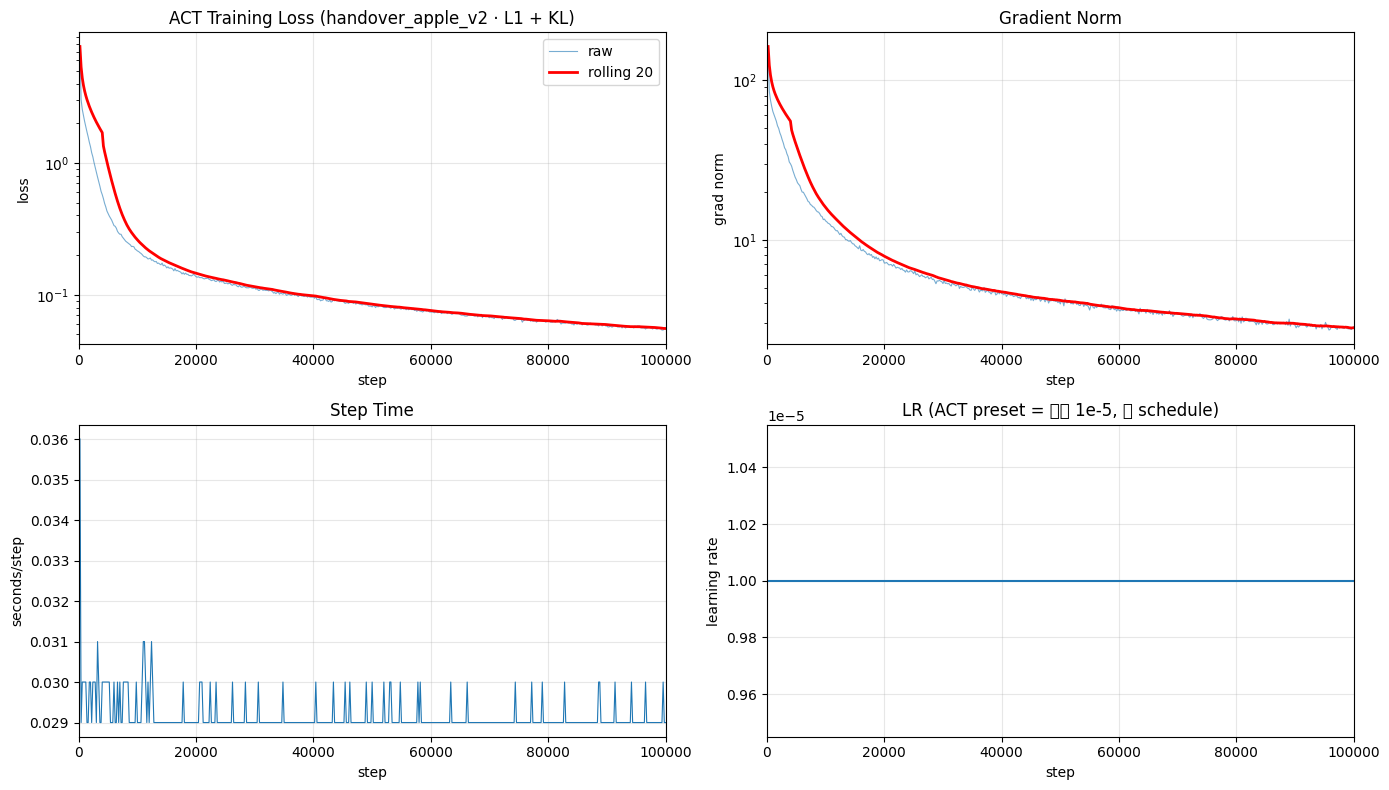

資料範圍：step 197 → 99998 / 100000（ACT 跑 step 0..99999，最後一點即最終 loss）


In [10]:
if len(df) > 5:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    _run = OUTPUT_DIR.name.replace('finetune_act_', '')  # e.g. handover_apple_v2

    axes[0, 0].plot(df['step'], df['loss'], lw=0.8, alpha=0.6, label='raw')
    axes[0, 0].plot(df['step'], df['loss'].rolling(20, min_periods=1).mean(), lw=2, color='red', label='rolling 20')
    axes[0, 0].set(xlabel='step', ylabel='loss', title=f'ACT Training Loss ({_run} · L1 + KL)')
    axes[0, 0].set_yscale('log')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    axes[0, 1].plot(df['step'], df['grdn'], lw=0.8, alpha=0.6)
    axes[0, 1].plot(df['step'], df['grdn'].rolling(20, min_periods=1).mean(), lw=2, color='red')
    axes[0, 1].set(xlabel='step', ylabel='grad norm', title='Gradient Norm')
    axes[0, 1].set_yscale('log')
    axes[0, 1].grid(True, alpha=0.3)

    axes[1, 0].plot(df['step'], df['step_s'], lw=0.8)
    axes[1, 0].set(xlabel='step', ylabel='seconds/step', title='Step Time')
    axes[1, 0].grid(True, alpha=0.3)

    axes[1, 1].plot(df['step'], df['lr'])
    axes[1, 1].set(xlabel='step', ylabel='learning rate', title='LR (ACT preset = 常數 1e-5, 無 schedule)')
    axes[1, 1].grid(True, alpha=0.3)

    # ★ x 軸固定到 TOTAL_STEPS，否則 matplotlib 自動縮放最後刻度常落在 90000，
    #   看起來像「沒跑到 100k」（其實資料最後一點在 step 99999 = 最終 loss，只差 1 步）
    for ax in axes.flat:
        ax.set_xlim(0, TOTAL_STEPS)

    plt.tight_layout()
    plt.show()
    print(f'資料範圍：step {int(df["step"].min())} → {int(df["step"].max())} / {TOTAL_STEPS}（ACT 跑 step 0..{TOTAL_STEPS-1}，最後一點即最終 loss）')
else:
    print('Not enough data points yet, wait for training to produce more log lines.')

## 3. Checkpoint 狀態

本 run `save_freq=10000, steps=100000` → 預期 **10 個** checkpoint（10000 … 100000）。

**1 epoch ≈ 8,200 steps**（apple_v2：65,477 frames / batch 8；strawberry/banana 相近）：

| ckpt | 對應 epoch | eval |
|---|---|---|
| 10000 | 1.2 | ○（早期，可能欠擬合）|
| 20000 | 2.4 | ○（v1 此點還 0%）|
| 30000 | 3.7 | ◎ sweep（甜蜜點候選）|
| **40000** | **4.9** | ◎ sweep（**v1 三果甜蜜點**）|
| **50000** | **6.1** | ◎ sweep |
| **60000** | **7.3** | ◎ sweep |
| 70000–100000 | 8.6–12.2 | △（unique_epochs 高、易 overfit，抽測看有無掉分）|

★ v2 是 trim 過的乾淨資料 + 100k 步 → unique_epochs≈12（v1 只有 5.9），**後段更可能 overfit**，甜蜜點可能仍在 40–60k，別預設 100k=最好。

→ 一次 sweep（各果換 fruit/dataset）：
`bash scripts/tools/eval_sweep_act.sh apple handover_apple_v2 10 040000 050000 060000 070000`
逐 ckpt：`bash scripts/tools/eval_act_fruit.sh apple handover_apple_v2 <ckpt> 10`。
ACT 有 temporal ensembling → 閉環應平滑；banana → **黃籃**（成功終點 y≈-0.18），歷史最難果要留意甩飛/沒抬起/回程 stall。

In [11]:
ckpt_dir = OUTPUT_DIR / 'checkpoints'
if ckpt_dir.exists():
    ckpts = sorted([p.name for p in ckpt_dir.iterdir() if p.is_dir() and p.name != 'last'])
    print(f'Saved checkpoints ({len(ckpts)}): {ckpts}')
    if ckpts:
        latest = ckpt_dir / ckpts[-1]
        size_gb = sum(p.stat().st_size for p in latest.rglob('*') if p.is_file()) / 1024**3
        print(f'Latest: {ckpts[-1]}  size={size_gb:.2f} GB')
    last_link = ckpt_dir / 'last'
    if last_link.exists():
        print(f"'last' symlink → {last_link.resolve().name if last_link.is_symlink() else 'dir'}")
else:
    print(f'No checkpoint dir yet at {ckpt_dir}')

Saved checkpoints (6): ['010000', '020000', '030000', '040000', '050000', '060000']
Latest: 060000  size=0.58 GB
'last' symlink → 060000


## 4. 系統資源（即時）

In [6]:
import subprocess
print('=== RAM ===')
print(subprocess.check_output(['free', '-h']).decode())
print('=== GPU ===')
print(subprocess.check_output([
    'nvidia-smi',
    '--query-gpu=memory.used,memory.free,memory.total,utilization.gpu,temperature.gpu',
    '--format=csv'
]).decode())
print('=== Training process ===')
try:
    out = subprocess.check_output(['pgrep', '-af', 'lerobot-train']).decode().strip()
    print(out if out else '(no lerobot-train process)')
except subprocess.CalledProcessError:
    print('(no lerobot-train process — possibly done or not started)')

=== RAM ===
               total        used        free      shared  buff/cache   available
Mem:            31Gi       8.4Gi       4.1Gi       385Mi        19Gi        22Gi
Swap:          8.0Gi       656Ki       8.0Gi

=== GPU ===
memory.used [MiB], memory.free [MiB], memory.total [MiB], utilization.gpu [%], temperature.gpu
2855 MiB, 21218 MiB, 24564 MiB, 89 %, 68

=== Training process ===
163544 /home/teddyminelab/miniconda3/bin/python /home/teddyminelab/miniconda3/condabin/conda run --no-capture-output -n lerobot lerobot-train --dataset.repo_id=handover_apple_v2 --dataset.root=datasets_lerobot/openarm/handover_apple_v2 --policy.type=act --policy.chunk_size=60 --policy.n_action_steps=1 --policy.temporal_ensemble_coeff=0.01 --policy.kl_weight=10 --policy.push_to_hub=false --policy.device=cuda --batch_size=8 --steps=100000 --save_freq=10000 --log_freq=200 --num_workers=4 --seed=42 --output_dir=outputs/finetune_act_handover_apple_v2 --job_name=act
163550 /home/teddyminelab/miniconda3/en